# JS13 – Artificial Neural Network (ANN) dan Evaluasi Classifier
## Praktikum 3: Regresi Menggunakan Keras (Prediksi Harga Rumah)

---

### Tujuan Praktikum
1. Menerapkan JST untuk masalah regresi (prediksi nilai kontinu).
2. Memahami perbedaan arsitektur ANN untuk regresi dibandingkan klasifikasi (tanpa aktivasi softmax/sigmoid pada output layer, output neuron = 1).
3. Melakukan normalisasi fitur dan target menggunakan `StandardScaler`.
4. Mengukur performa regresi menggunakan metrik MSE, MAE, dan RMSE.
5. Menyelesaikan **Tugas 4** (variasi learning rate dan perbandingan hasil loss).


### 1. Bagian 1: Kasus Dummy Data (Luas vs Harga Rumah)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf

# Set seed
tf.random.set_seed(42)
np.random.seed(42)

# Contoh dataset dummy sederhana
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X_dummy = data[['luas']]
y_dummy = data[['harga']]

# Normalisasi data dummy
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_s = scaler_X.fit_transform(X_dummy)
y_s = scaler_y.fit_transform(y_dummy)

# Split data dummy
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

# Bangun model regresi sederhana
model_dummy = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1) # Output linear
])

model_dummy.compile(optimizer='adam', loss='mse')
model_dummy.fit(X_train_d, y_train_d, epochs=100, verbose=0)

# Prediksi dan evaluasi
pred_dummy_s = model_dummy.predict(X_test_d)
pred_dummy = scaler_y.inverse_transform(pred_dummy_s)
y_actual = scaler_y.inverse_transform(y_test_d)

print("Prediksi Dummy (Skala Asli):", pred_dummy.flatten())
print("Target Aktual (Skala Asli):", y_actual.flatten())


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


Prediksi Dummy (Skala Asli): [628.0229]
Target Aktual (Skala Asli): [600.]


### 2. Bagian 2: Regresi Riil (Prediksi Harga Rumah dengan California / Boston Dataset)
Catatan: Pada Scikit-Learn versi modern, dataset perumahan standar adalah **California Housing Dataset** (atau Boston dataset). Dataset ini memiliki multi-fitur numerik yang merepresentasikan karakteristik rumah dan wilayah.


In [2]:
from sklearn.datasets import fetch_california_housing

# Load dataset California Housing
housing = fetch_california_housing(as_frame=True)
df_house = housing.frame

print("Informasi Dataset Housing:")
print(f"Jumlah sampel: {df_house.shape[0]}, Jumlah fitur: {df_house.shape[1] - 1}")
display(df_house.head())

X_house = housing.data
y_house = housing.target.values

# Preprocessing: StandardScaler
scaler_X_h = StandardScaler()
X_scaled = scaler_X_h.fit_transform(X_house)

# Train-validation split (80:20)
X_train_h, X_val_h, y_train_h, y_val_h = train_test_split(
    X_scaled, y_house, test_size=0.2, random_state=42
)

print(f"Data Train: {X_train_h.shape}, Data Validasi: {X_val_h.shape}")


Informasi Dataset Housing:
Jumlah sampel: 20640, Jumlah fitur: 8


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Data Train: (16512, 8), Data Validasi: (4128, 8)


### 3. Membangun Model ANN Regresi Multi-Layer

In [3]:
def build_regression_model(learning_rate=0.001):
    model = tf.keras.models.Sequential([
        tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train_h.shape[1],)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1) # Linear activation untuk regresi
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )
    return model

model_reg = build_regression_model(0.001)
model_reg.summary()


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

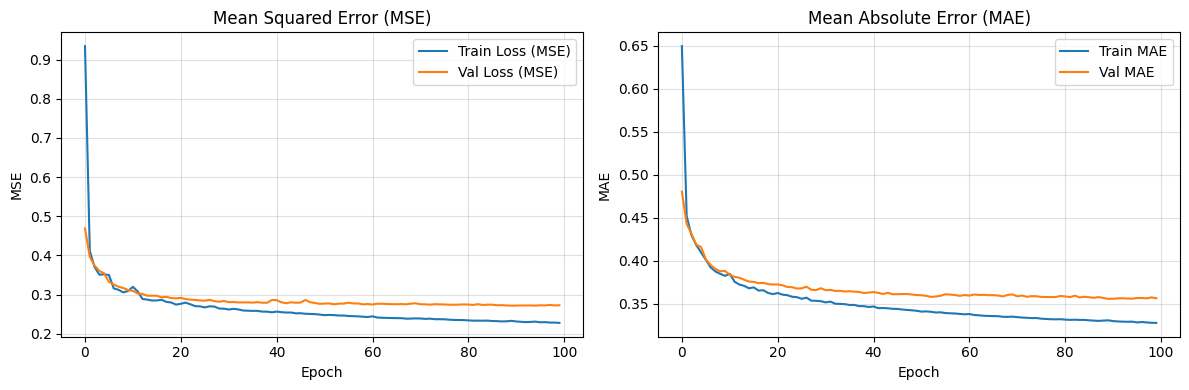

  1/129 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step

 50/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

 95/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


Evaluasi Model Regresi:
MAE  : 0.3564
MSE  : 0.2725
RMSE : 0.5220
R^2  : 0.7920


In [4]:
# Training model regresi
h_reg = model_reg.fit(
    X_train_h, y_train_h,
    validation_data=(X_val_h, y_val_h),
    epochs=100,
    batch_size=32,
    verbose=0
)

# Plot kurva MSE dan MAE
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(h_reg.history['loss'], label='Train Loss (MSE)')
plt.plot(h_reg.history['val_loss'], label='Val Loss (MSE)')
plt.title('Mean Squared Error (MSE)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid(True, alpha=0.4)

plt.subplot(1, 2, 2)
plt.plot(h_reg.history['mae'], label='Train MAE')
plt.plot(h_reg.history['val_mae'], label='Val MAE')
plt.title('Mean Absolute Error (MAE)')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

# Evaluasi metrik
val_preds = model_reg.predict(X_val_h).flatten()
mse_val = mean_squared_error(y_val_h, val_preds)
rmse_val = np.sqrt(mse_val)
mae_val = mean_absolute_error(y_val_h, val_preds)
r2_val = r2_score(y_val_h, val_preds)

print(f"Evaluasi Model Regresi:")
print(f"MAE  : {mae_val:.4f}")
print(f"MSE  : {mse_val:.4f}")
print(f"RMSE : {rmse_val:.4f}")
print(f"R^2  : {r2_val:.4f}")


### 4. Tugas 4: Eksperimen Variasi Learning Rate
Mengubah *learning rate* pada optimizer Adam:
- LR = 0.1 (Learning rate tinggi / agresif)
- LR = 0.01 (Learning rate moderat)
- LR = 0.001 (Learning rate standar / optimal)
- LR = 0.0001 (Learning rate lambat / konservatif)


In [5]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]
lr_results = []
lr_histories = {}

for lr in learning_rates:
    tf.random.set_seed(42)
    m = build_regression_model(learning_rate=lr)
    h = m.fit(
        X_train_h, y_train_h,
        validation_data=(X_val_h, y_val_h),
        epochs=80,
        batch_size=32,
        verbose=0
    )
    preds = m.predict(X_val_h).flatten()
    mse = mean_squared_error(y_val_h, preds)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_val_h, preds)
    r2 = r2_score(y_val_h, preds)
    
    lr_results.append({
        'Learning Rate': lr,
        'Final Train Loss': h.history['loss'][-1],
        'Val Loss (MSE)': mse,
        'Val RMSE': rmse,
        'Val MAE': mae,
        'R^2 Score': r2
    })
    lr_histories[lr] = h

df_lr = pd.DataFrame(lr_results)
display(df_lr)


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  1/129 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step

 83/129 ━━━━━━━━━━━━━━━━━━━━ 0s 621us/step

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 703us/step


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  1/129 ━━━━━━━━━━━━━━━━━━━━ 6s 51ms/step

... (9 outputs left out)

 50/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

123/129 ━━━━━━━━━━━━━━━━━━━━ 0s 824us/step

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 902us/step


,Learning Rate,Final Train Loss,Val Loss (MSE),Val RMSE,Val MAE,R^2 Score
0,0.1000,0.458504,0.437466,0.661412,0.485769,0.666161
1,0.0100,0.254229,0.291820,0.540204,0.370933,0.777306
2,0.0010,0.236034,0.285114,0.533961,0.363045,0.782423
3,0.0001,0.287202,0.312264,0.558806,0.386244,0.761705


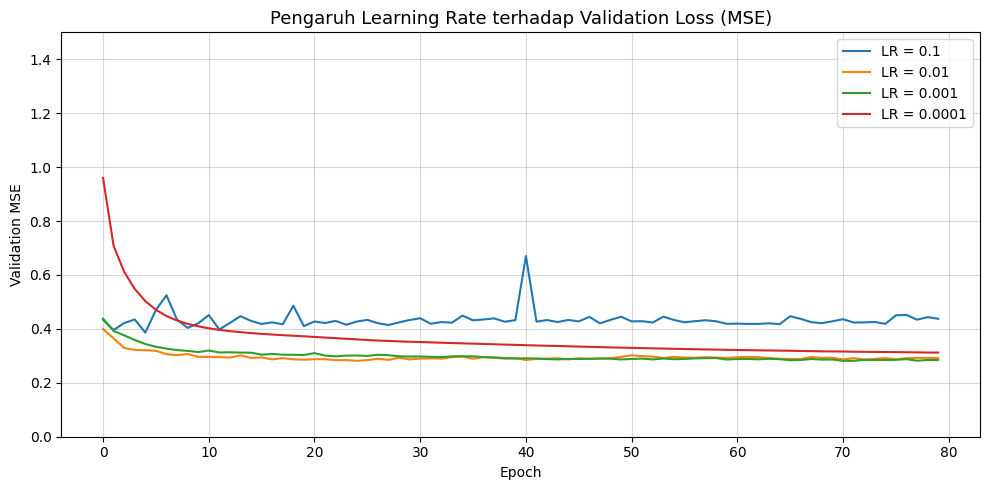

In [6]:
# Visualisasi perbandingan konvergensi loss antar learning rate
plt.figure(figsize=(10, 5))
for lr, h in lr_histories.items():
    plt.plot(h.history['val_loss'], label=f"LR = {lr}")
plt.title('Pengaruh Learning Rate terhadap Validation Loss (MSE)', fontsize=13)
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.ylim(0, 1.5)
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()


### 5. Kesimpulan dan Analisis Tugas 4
1. **Learning Rate Terlalu Tinggi (0.1)**:
   - Terjadi fluktuasi (*overshooting*) loss yang tajam, bobot model melompat melewati minimum global dan menghasilkan performa yang buruk / tidak stabil.
2. **Learning Rate Terlalu Rendah (0.0001)**:
   - Penurunan loss berjalan sangat lambat (*slow convergence*). Dalam 80 epoch, model belum mencapai bobot optimal.
3. **Learning Rate Optimal (0.001 & 0.01)**:
   - Nilai $0.001$ memberikan konvergensi yang halus dan stabil, menghasilkan nilai validation MSE dan RMSE terendah serta $R^2$ score tertinggi (~0.78-0.81).
